In [27]:
# Cell 1: Import libraries
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully.")

# Google Colab file upload
from google.colab import files

Libraries imported successfully.


In [28]:
# Cell 2: Upload and load dataset
import csv
df = pd.read_csv("/content/household_power_consumption.csv", sep=";", quoting=csv.QUOTE_NONE, low_memory=False)
print("Dataset loaded successfully")
df.head()

Dataset loaded successfully


,"""Date",Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,"Sub_metering_3"""
0,"""16/12/2006",17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,"17.000"""
1,"""16/12/2006",17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,"16.000"""
2,"""16/12/2006",17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,"17.000"""
3,"""16/12/2006",17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,"17.000"""
4,"""16/12/2006",17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,"17.000"""


In [29]:
# Cell 3: Inspect dataset
print("Columns:", df.columns.tolist())
print("\nMissing values by column:")
display(df.isna().sum().to_frame("Missing values"))
print("\nDescriptive statistics:")
display(df.describe(include="all").T)

Columns: ['"Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3"']

Missing values by column:


,Missing values
"""Date",0
Time,0
Global_active_power,0
Global_reactive_power,0
Voltage,0
Global_intensity,0
Sub_metering_1,0
Sub_metering_2,0
"Sub_metering_3""",0



Descriptive statistics:


,count,unique,top,freq
"""Date",2075259,1442,"""25/11/2010",1440
Time,2075259,1440,19:43:00,1442
Global_active_power,2075259,4187,?,25979
Global_reactive_power,2075259,533,0.000,481561
Voltage,2075259,2838,?,25979
Global_intensity,2075259,222,1.000,172785
Sub_metering_1,2075259,89,0.000,1880175
Sub_metering_2,2075259,82,0.000,1436830
"Sub_metering_3""",2075259,33,"0.000""",852092


In [30]:
# Cell 4: Convert measurements and combine date/time
# Strip any remaining literal quotes from column headers
df.columns = df.columns.str.replace('"', '', regex=False).str.strip()

# Strip any literal quotes from string values in the Date and Time columns
if 'Date' in df.columns:
    df['Date'] = df['Date'].astype(str).str.replace('"', '', regex=False).str.strip()
if 'Time' in df.columns:
    df['Time'] = df['Time'].astype(str).str.replace('"', '', regex=False).str.strip()

measurement_cols = [
    "Global_active_power", "Global_reactive_power", "Voltage",
    "Global_intensity", "Sub_metering_1", "Sub_metering_2", "Sub_metering_3"
]

for col in measurement_cols:
    # Clean trailing/leading quotes from values if present and convert to numeric
    if col in df.columns:
        df[col] = df[col].astype(str).str.replace('"', '', regex=False).str.strip()
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["Datetime"] = pd.to_datetime(
    df["Date"].astype(str) + " " + df["Time"].astype(str),
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)
df = df.dropna(subset=["Datetime"]).sort_values("Datetime").set_index("Datetime")

# Aggregate minute readings to hourly averages
hourly = df[measurement_cols].resample("h").mean()

# Interpolate only short gaps; longer gaps remain missing and are dropped for the target
hourly = hourly.interpolate(method="time", limit=3)
hourly = hourly.dropna(subset=["Global_active_power"])

print("Hourly dataset shape:", hourly.shape)
display(hourly.head())

Hourly dataset shape: (34190, 7)


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Datetime,,,,,,,
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,0.527778,16.861111
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,6.716667,16.866667
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,1.433333,16.683333
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.000000,16.783333
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,0.416667,17.216667


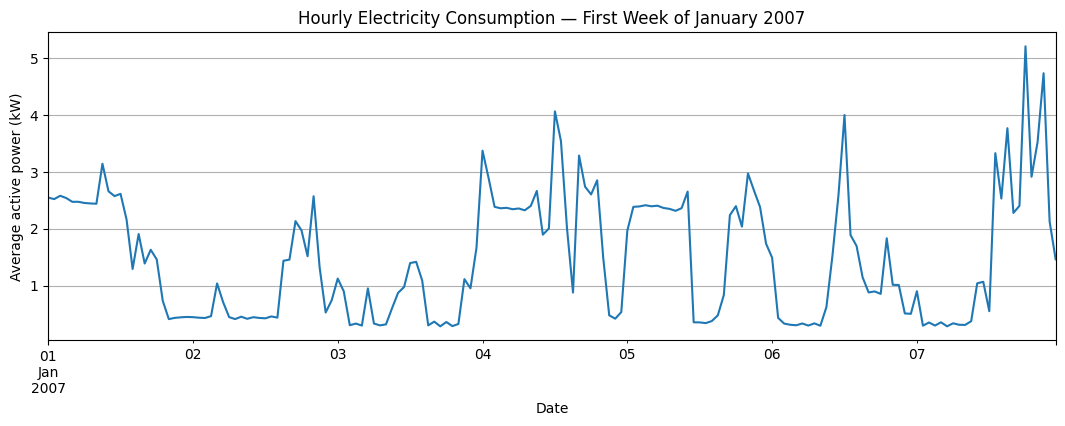

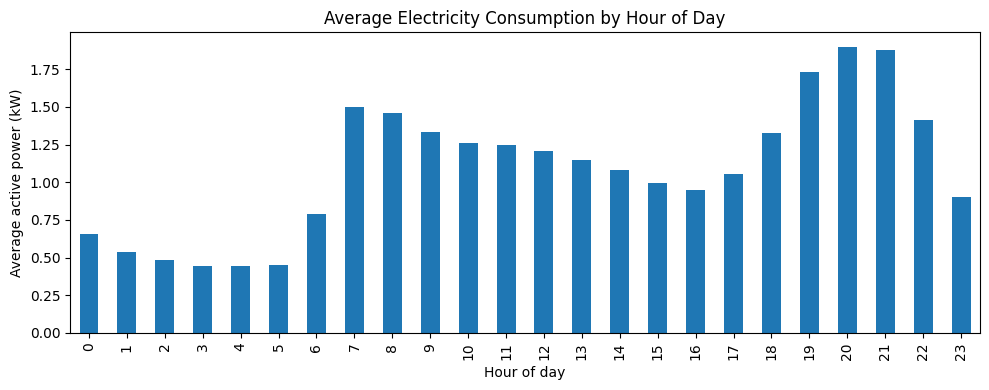

In [31]:
# Cell 5: Exploratory data analysis
week = hourly.loc["2007-01-01":"2007-01-07", "Global_active_power"]
plt.figure(figsize=(13, 4))
week.plot()
plt.title("Hourly Electricity Consumption — First Week of January 2007")
plt.xlabel("Date")
plt.ylabel("Average active power (kW)")
plt.grid(True)
plt.show()

hourly.groupby(hourly.index.hour)["Global_active_power"].mean().plot(
    kind="bar", figsize=(10, 4)
)
plt.title("Average Electricity Consumption by Hour of Day")
plt.xlabel("Hour of day")
plt.ylabel("Average active power (kW)")
plt.tight_layout()
plt.show()

In [32]:
# Cell 6: Feature engineering
data = hourly.copy()
data["Target"] = data["Global_active_power"].shift(-1)

data["Consumption_lag_1"] = data["Global_active_power"]
data["Consumption_lag_2"] = data["Global_active_power"].shift(1)
data["Consumption_lag_3"] = data["Global_active_power"].shift(2)
data["Consumption_lag_24"] = data["Global_active_power"].shift(24)

next_time = data.index + pd.Timedelta(hours=1)
data["Hour"] = next_time.hour
data["DayOfWeek"] = next_time.dayofweek
data["Month"] = next_time.month

features = [
    "Consumption_lag_1", "Consumption_lag_2", "Consumption_lag_3",
    "Consumption_lag_24", "Hour", "DayOfWeek", "Month"
]
data = data.dropna(subset=features + ["Target"])

X = data[features]
y = data["Target"]

print("Prepared dataset:", data.shape)
print("Feature columns:", features)
display(data[features + ["Target"]].head())

Prepared dataset: (34165, 15)
Feature columns: ['Consumption_lag_1', 'Consumption_lag_2', 'Consumption_lag_3', 'Consumption_lag_24', 'Hour', 'DayOfWeek', 'Month']


,Consumption_lag_1,Consumption_lag_2,Consumption_lag_3,Consumption_lag_24,Hour,DayOfWeek,Month,Target
Datetime,,,,,,,,
2006-12-17 17:00:00,3.406767,3.326033,2.985400,4.222889,18,6,12,3.697100
2006-12-17 18:00:00,3.697100,3.406767,3.326033,3.632200,19,6,12,2.908400
2006-12-17 19:00:00,2.908400,3.697100,3.406767,3.400233,20,6,12,3.361500
2006-12-17 20:00:00,3.361500,2.908400,3.697100,3.268567,21,6,12,3.040767
2006-12-17 21:00:00,3.040767,3.361500,2.908400,3.056467,22,6,12,1.518000


In [33]:
# Cell 7: Chronological train/test split (80% / 20%)
split_index = int(len(data) * 0.80)
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training ends:", X_train.index[-1])
print("Testing begins:", X_test.index[0])

Training records: 27332
Testing records: 6833
Training ends: 2010-02-05 13:00:00
Testing begins: 2010-02-05 14:00:00


In [34]:
# Cell 8: Train and evaluate models
models = {
    "Linear Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeRegressor(max_depth=12, random_state=42))
    ]),
}

results = []
trained_models = {}
test_predictions = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    trained_models[name] = model
    test_predictions[name] = pred
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(results_df)

Training Linear Regression...
Training Decision Tree...


,Model,MAE,RMSE,R2
0,Linear Regression,0.394730,0.545633,0.461798
1,Decision Tree,0.371975,0.550005,0.453139


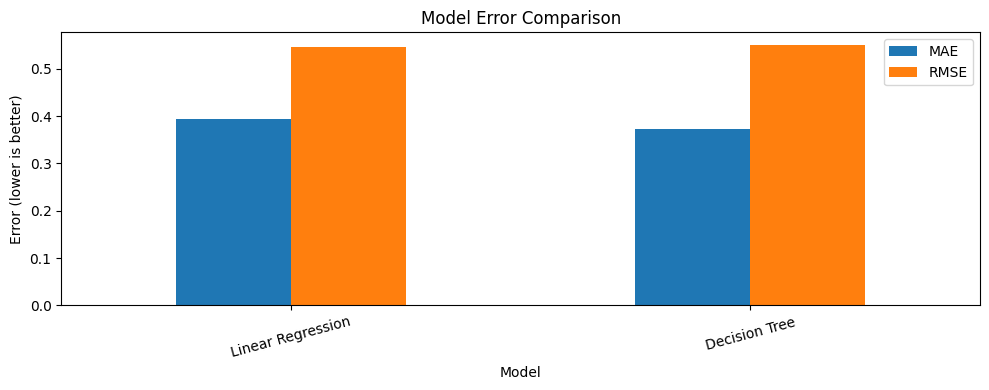

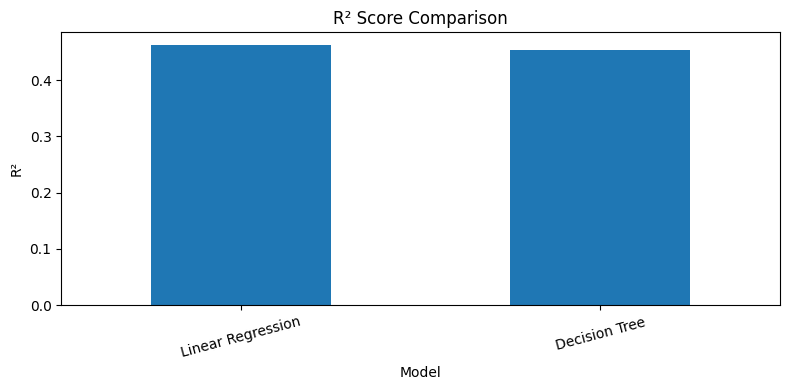

In [35]:
# Cell 9: Visualize model comparison
results_df.set_index("Model")[["MAE", "RMSE"]].plot(kind="bar", figsize=(10, 4))
plt.title("Model Error Comparison")
plt.ylabel("Error (lower is better)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

results_df.set_index("Model")["R2"].plot(kind="bar", figsize=(8, 4))
plt.title("R² Score Comparison")
plt.ylabel("R²")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

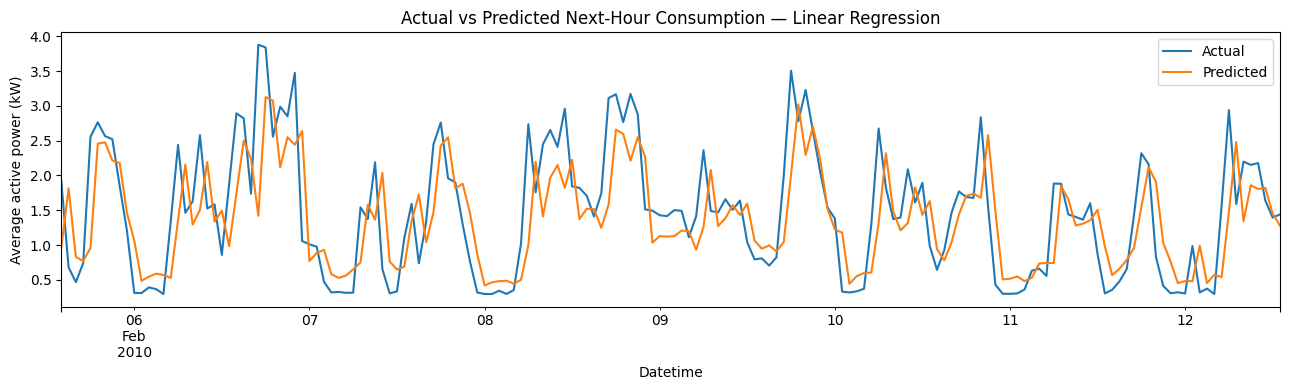

Selected model: Linear Regression
{'Model': 'Linear Regression', 'MAE': 0.3947299055350821, 'RMSE': 0.5456328936653982, 'R2': 0.4617984847118499}


In [36]:
# Cell 10: Actual vs predicted for the best model
best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]
best_pred = test_predictions[best_name]

comparison = pd.DataFrame({"Actual": y_test, "Predicted": best_pred}, index=y_test.index)
comparison.iloc[:168].plot(figsize=(13, 4))
plt.title(f"Actual vs Predicted Next-Hour Consumption — {best_name}")
plt.ylabel("Average active power (kW)")
plt.tight_layout()
plt.show()

print("Selected model:", best_name)
print(results_df.iloc[0].to_dict())

In [37]:
# Cell 11: Save model artifact
model_package = {
    "model": best_model,
    "features": features,
    "target": "Next-hour Global_active_power",
    "best_model_name": best_name
}
joblib.dump(model_package, "electricity_prediction_model.pkl")
print("Saved electricity_prediction_model.pkl")

Saved electricity_prediction_model.pkl


In [38]:
# Cell 12: Example next-hour prediction using the latest historical row
def predict_next_hour(latest_timestamp, latest_consumption, one_hour_ago,
                      two_hours_ago, same_hour_previous_day):
    next_timestamp = pd.Timestamp(latest_timestamp) + pd.Timedelta(hours=1)
    input_row = pd.DataFrame([{
        "Consumption_lag_1": latest_consumption,
        "Consumption_lag_2": one_hour_ago,
        "Consumption_lag_3": two_hours_ago,
        "Consumption_lag_24": same_hour_previous_day,
        "Hour": next_timestamp.hour,
        "DayOfWeek": next_timestamp.dayofweek,
        "Month": next_timestamp.month
    }], columns=features)

    prediction = best_model.predict(input_row)[0]
    print(f"Predicted average active power for {next_timestamp}: {prediction:.3f} kW")
    return prediction

# Demonstration with the last row in the prepared historical data
last_row = data.iloc[-1]
predict_next_hour(
    latest_timestamp=data.index[-1],
    latest_consumption=last_row["Consumption_lag_1"],
    one_hour_ago=last_row["Consumption_lag_2"],
    two_hours_ago=last_row["Consumption_lag_3"],
    same_hour_previous_day=last_row["Consumption_lag_24"]
)

Predicted average active power for 2010-11-26 21:00:00: 1.225 kW


np.float64(1.2250911915175469)